# Дополнительное задание. Прогнозирование временных рядов

**Цель:** освоить базовый пайплайн прогнозирования временного ряда через сведение к задаче регрессии.

**Датасет:** [Daily Website Visitors](https://www.kaggle.com/datasets/bobnau/daily-website-visitors) (Kaggle) — ежедневная посещаемость учебного сайта по статистическому прогнозированию с сентября 2014 по август 2020.

**Задача:** прогнозировать `Page.Loads` — число просмотров страниц за день. Каждую дату описываем признаками, построенными только по прошлым значениям ряда и по календарю, и решаем задачу регрессии.

## 1. Загрузка и визуализация

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from statsmodels.tsa.seasonal import STL, MSTL

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

df = pd.read_csv('daily-website-visitors.csv', thousands=',')
print('Размер датасета:', df.shape)
df.head()

Размер датасета: (2167, 8)


,Row,Day,Day.Of.Week,Date,Page.Loads,Unique.Visits,First.Time.Visits,Returning.Visits
0,1,Sunday,1,9/14/2014,2146,1582,1430,152
1,2,Monday,2,9/15/2014,3621,2528,2297,231
2,3,Tuesday,3,9/16/2014,3698,2630,2352,278
3,4,Wednesday,4,9/17/2014,3667,2614,2327,287
4,5,Thursday,5,9/18/2014,3316,2366,2130,236


В датасете 2167 дней и 8 столбцов:

| Столбец | Описание |
|---|---|
| `Row` | номер строки |
| `Day`, `Day.Of.Week` | день недели названием и номером (1 — воскресенье) |
| `Date` | дата |
| `Page.Loads` | просмотры страниц за день — **целевая переменная** |
| `Unique.Visits` | уникальные посетители за день |
| `First.Time.Visits` | новые посетители |
| `Returning.Visits` | вернувшиеся посетители |

Числа в файле записаны с разделителем тысяч (`2,146`), поэтому при чтении указан `thousands=','`.

Столбцы `Unique.Visits`, `First.Time.Visits` и `Returning.Visits` в признаки не берём: они измеряются в тот же день, что и `Page.Loads`, и на момент прогноза неизвестны. Их использование было бы утечкой из будущего. День недели строим заново из даты.

In [2]:
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y')
df = df.sort_values('Date').set_index('Date')

full_range = pd.date_range(df.index.min(), df.index.max(), freq='D')
print('Период:', df.index.min().date(), '—', df.index.max().date())
print('Пропущенных дат:', len(full_range) - len(df))
print('Повторяющихся дат:', df.index.duplicated().sum())
print('Пропусков в Page.Loads:', df['Page.Loads'].isna().sum())

y = df['Page.Loads'].asfreq('D').astype(float)
y.describe().round(1)

Период: 2014-09-14 — 2020-08-19
Пропущенных дат: 0
Повторяющихся дат: 0
Пропусков в Page.Loads: 0


count    2167.0
mean     4117.0
std      1351.0
min      1002.0
25%      3114.5
50%      4106.0
75%      5020.5
max      7984.0
Name: Page.Loads, dtype: float64

Ряд полный: ни одна дата не пропущена и не повторяется, пропусков в целевой переменной нет. Индекс переведён в `datetime` с частотой 1 день и отсортирован по времени.

Просмотров в день от 1002 до 7984, в среднем 4117, стандартное отклонение 1351 — разброс большой, около трети среднего.

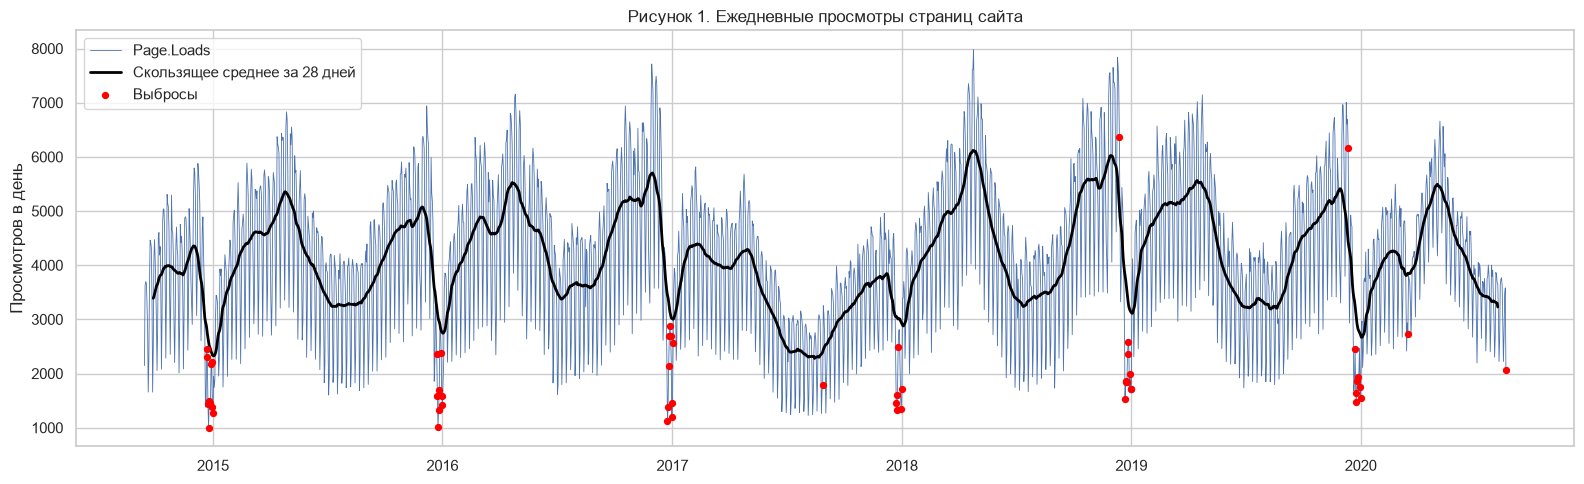

In [3]:
DAYS = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']

# выброс — день, который сильно отличается от медианы того же дня недели за соседние ±3 недели;
# центрированная медиана использует будущее, поэтому она нужна только для анализа и в признаки не попадает
same_dow_median = y.groupby(y.index.dayofweek).transform(lambda s: s.rolling(7, center=True, min_periods=4).median())
ratio = y / same_dow_median
outliers = y[(ratio < 0.65) | (ratio > 1.4)]

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(y, lw=0.6, label='Page.Loads')
ax.plot(y.rolling(28, center=True).mean(), color='black', lw=2, label='Скользящее среднее за 28 дней')
ax.scatter(outliers.index, outliers, color='red', s=18, zorder=3, label='Выбросы')
ax.set_title('Рисунок 1. Ежедневные просмотры страниц сайта')
ax.set_ylabel('Просмотров в день')
ax.legend()
plt.tight_layout()
plt.show()

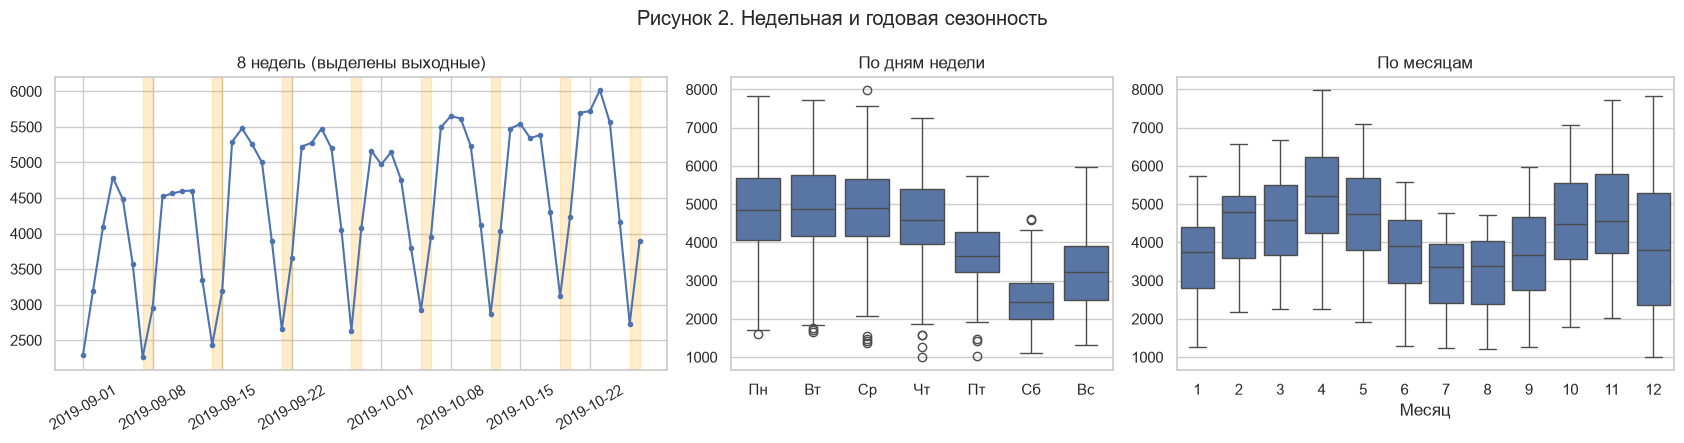

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), gridspec_kw={'width_ratios': [1.6, 1, 1.3]})
sample = y['2019-09-01':'2019-10-27']
axes[0].plot(sample, marker='o', ms=3)
for d in sample.index[sample.index.dayofweek == 5]:
    axes[0].axvspan(d, d + pd.Timedelta(days=1), color='orange', alpha=0.2)
axes[0].set_title('8 недель (выделены выходные)')
axes[0].tick_params(axis='x', rotation=30)

sns.boxplot(x=y.index.dayofweek, y=y.values, ax=axes[1])
axes[1].set_xticks(range(7), DAYS)
axes[1].set_xlabel('')
axes[1].set_title('По дням недели')

sns.boxplot(x=y.index.month, y=y.values, ax=axes[2])
axes[2].set_title('По месяцам')
axes[2].set_xlabel('Месяц')
fig.suptitle('Рисунок 2. Недельная и годовая сезонность')
plt.tight_layout()
plt.show()

In [5]:
yearly = y.groupby(y.index.year).agg(['mean', 'count']).round(0)
yearly.columns = ['Среднее в день', 'Число дней']
yearly.T

Date,2014,2015,2016,2017,2018,2019,2020
Среднее в день,3650.0,4083.0,4422.0,3396.0,4500.0,4345.0,4081.0
Число дней,109.0,365.0,366.0,365.0,365.0,365.0,232.0


In [6]:
holidays = USFederalHolidayCalendar().holidays('2014-01-01', '2021-12-31', return_name=True)
in_xmas = ((outliers.index.month == 12) & (outliers.index.day >= 20)) | ((outliers.index.month == 1) & (outliers.index.day <= 2))
print('Всего выбросов:', len(outliers))
print('Из них с 20 декабря по 2 января:', in_xmas.sum())

other = outliers[~in_xmas]
pd.DataFrame({
    'Page.Loads': other,
    'Доля от медианы': ratio[other.index].round(2),
    'День недели': [DAYS[d] for d in other.index.dayofweek],
})

Всего выбросов: 54
Из них с 20 декабря по 2 января: 49


,Page.Loads,Доля от медианы,День недели
Date,,,
2017-08-28,1786.0,0.65,Пн
2018-12-13,6373.0,1.43,Чт
2019-12-12,6163.0,1.47,Чт
2020-03-16,2732.0,0.56,Пн
2020-08-19,2064.0,0.55,Ср


**Рисунки 1–2 и таблицы.**

- **Недельная сезонность — самая сильная.** С понедельника по среду медиана около 4900 просмотров, в четверг около 4600, в пятницу 3650, в субботу минимум — около 2450, в воскресенье 3250. Цикл повторяется каждую неделю без исключений (левый график рисунка 2).
- **Годовая сезонность.** Посещаемость следует учебному году: максимум в апреле (медиана около 5200) и в октябре–ноябре, минимум летом — в июле и августе около 3350. Резкий провал каждый год на рождественских каникулах, после него в январе быстрый рост. Сайт учебный, поэтому посещаемость зависит от семестров.
- **Тренд слабый и нелинейный.** Среднее в день росло с 4083 в 2015 году до 4422 в 2016, в 2017 году упало до 3396 (на рисунке 1 видно, что весь 2017 год ниже соседних), в 2018 вернулось к 4500, затем держится около 4100–4350. Годы 2014 и 2020 неполные, их средние зависят от того, какие месяцы попали в данные.
- **Выбросы.** Выбросом считаем день, который отличается от медианы того же дня недели за соседние ±3 недели меньше чем в 0.65 раза или больше чем в 1.4 раза. Из 54 таких дней 49 приходятся на 20 декабря — 2 января: в Рождество и Новый год просмотров в 2–3 раза меньше обычного. Остальные пять:
  - 13.12.2018 и 12.12.2019 — всплески перед экзаменами в конце семестра (в 1.4–1.5 раза выше обычного);
  - 28.08.2017 — одиночный провал в понедельник, ровно на границе порога (0.65);
  - 16.03.2020 — понедельник, когда университеты США переходили на дистанционное обучение из-за COVID-19;
  - 19.08.2020 — последний день ряда; 2064 просмотра для среды — очень мало, скорее всего, данные за этот день выгружены не полностью.

Выбросы не удаляем: праздники повторяются каждый год, и модель должна уметь их прогнозировать. Для этого добавим календарные признаки праздника и рождественских каникул.

## 2. Признаки

Для каждой даты $t$ строим признаки только из значений ряда до $t$ (не включая $t$) и из календаря — календарь на будущее известен заранее.

| Группа | Признаки |
|---|---|
| Календарные | день недели и месяц (one-hot), год, выходной, федеральный праздник США, рождественские каникулы (20.12–2.01) |
| Лаги | $y_{t-1}, \dots, y_{t-7}$ |
| Скользящие статистики | среднее, медиана, стандартное отклонение, min и max за 7 и 28 дней, окно заканчивается в $t-1$ |
| Сезонные | значение неделю ($y_{t-7}$), две недели ($y_{t-14}$) и год назад ($y_{t-364}$), среднее за 4 прошлых таких же дня недели |

Год назад берём 364 дня, а не 365: 364 = 52 недели, поэтому это тот же день недели. Для ряда с сильной недельной сезонностью это важно: 365 дней назад от понедельника — воскресенье. Праздники взяты по календарю США, так как сайт американский.

День недели и месяц кодируем one-hot, а не числом: для линейной модели номер дня 0–6 означал бы, что воскресенье «в 6 раз больше» понедельника.

In [7]:
HOLIDAYS = USFederalHolidayCalendar().holidays('2014-01-01', '2021-12-31')
LAGS = range(1, 8)
WINDOWS = (7, 28)
SEASONAL_LAGS = {'week_ago': 7, 'two_weeks_ago': 14, 'year_ago': 364}


def make_features(y):
    """Признаки для каждой даты ряда y. В строке t используются только значения y до t (не включая t)."""
    idx = y.index
    X = pd.DataFrame(index=idx)

    # календарные: день недели и месяц — one-hot (базовые категории — понедельник и январь)
    for d in range(1, 7):
        X[f'dow_{d}'] = (idx.dayofweek == d).astype(int)
    for m in range(2, 13):
        X[f'month_{m}'] = (idx.month == m).astype(int)
    X['year'] = idx.year
    X['is_weekend'] = (idx.dayofweek >= 5).astype(int)
    X['is_holiday'] = idx.isin(HOLIDAYS).astype(int)
    X['xmas_break'] = (((idx.month == 12) & (idx.day >= 20)) | ((idx.month == 1) & (idx.day <= 2))).astype(int)

    # лаги y[t-1], ..., y[t-7]
    for lag in LAGS:
        X[f'lag_{lag}'] = y.shift(lag)

    # скользящие статистики по окну, которое заканчивается в t-1
    past = y.shift(1)
    for w in WINDOWS:
        roll = past.rolling(w)
        X[f'roll_mean_{w}'] = roll.mean()
        X[f'roll_median_{w}'] = roll.median()
        X[f'roll_std_{w}'] = roll.std()
        X[f'roll_min_{w}'] = roll.min()
        X[f'roll_max_{w}'] = roll.max()

    # сезонные: значение неделю, две недели и год назад (364 дня — тот же день недели)
    for name, lag in SEASONAL_LAGS.items():
        X[name] = y.shift(lag)
    X['same_dow_mean_4'] = (y.shift(7) + y.shift(14) + y.shift(21) + y.shift(28)) / 4
    return X


X_all = make_features(y)
data = X_all.assign(target=y).dropna()
FEATURES = list(X_all.columns)
print('Признаков:', len(FEATURES))
print('Строк с полным набором признаков:', len(data), f'(с {data.index.min().date()})')

Признаков: 42
Строк с полным набором признаков: 1803 (с 2015-09-13)


In [8]:
# проверка на утечку: признаки для даты t не меняются, если «испортить» значение y[t] и все последующие
t = data.index[1000]
y_spoiled = y.copy()
y_spoiled[t:] = -1
print('Признаки не зависят от будущего:', make_features(y_spoiled).loc[t].equals(X_all.loc[t]))
data.loc[[t], ['lag_1', 'lag_7', 'roll_mean_7', 'roll_std_28', 'year_ago', 'same_dow_mean_4', 'is_holiday', 'target']]

Признаки не зависят от будущего: True


,lag_1,lag_7,roll_mean_7,roll_std_28,year_ago,same_dow_mean_4,is_holiday,target
Date,,,,,,,,
2018-06-09,3956.0,2511.0,4291.571429,1095.389614,1655.0,2838.5,0,2303.0


Получено 42 признака. Для лага 364 нужен год истории, поэтому первые 364 дня отбрасываются: остаётся 1803 дня с 13.09.2015.

Отсутствие утечки проверено напрямую: если заменить значение ряда в дату $t$ и все последующие на −1, признаки для $t$ не меняются. Значит, каждый признак строится только по прошлому.

## 3. Разделение и кросс-валидация

In [9]:
TEST_DAYS = 182
train, test = data.iloc[:-TEST_DAYS], data.iloc[-TEST_DAYS:]
X_train, y_train = train[FEATURES], train['target']
X_test, y_test = test[FEATURES], test['target']

print(f'Обучающая выборка: {len(train)} дней, {train.index.min().date()} — {train.index.max().date()}')
print(f'Тестовая выборка:  {len(test)} дней, {test.index.min().date()} — {test.index.max().date()}')

Обучающая выборка: 1621 дней, 2015-09-13 — 2020-02-19
Тестовая выборка:  182 дней, 2020-02-20 — 2020-08-19


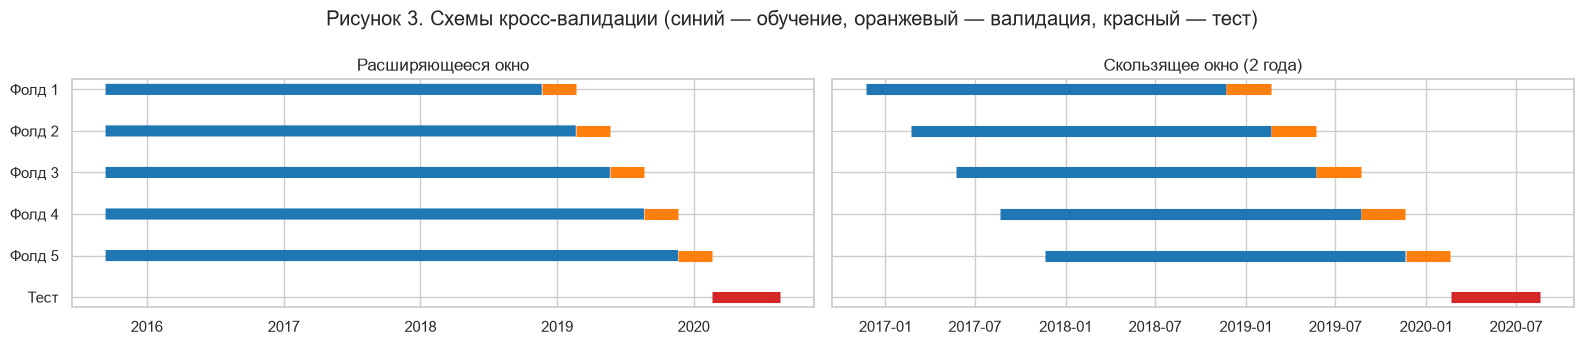

In [10]:
tscv = TimeSeriesSplit(n_splits=5, test_size=91)
tscv_sliding = TimeSeriesSplit(n_splits=5, test_size=91, max_train_size=730)

fig, axes = plt.subplots(1, 2, figsize=(16, 3.5), sharey=True)
for ax, cv, title in zip(axes, [tscv, tscv_sliding], ['Расширяющееся окно', 'Скользящее окно (2 года)']):
    for k, (tr, va) in enumerate(cv.split(X_train)):
        ax.plot(X_train.index[tr], [k] * len(tr), color='tab:blue', lw=8, solid_capstyle='butt')
        ax.plot(X_train.index[va], [k] * len(va), color='tab:orange', lw=8, solid_capstyle='butt')
    ax.plot(X_test.index, [5] * len(X_test), color='tab:red', lw=8, solid_capstyle='butt')
    ax.set_title(title)
axes[0].set_yticks(range(6), [f'Фолд {k}' for k in range(1, 6)] + ['Тест'])
axes[0].invert_yaxis()
fig.suptitle('Рисунок 3. Схемы кросс-валидации (синий — обучение, оранжевый — валидация, красный — тест)')
plt.tight_layout()
plt.show()

Ряд разделён по времени без перемешивания: последние 182 дня (полгода, 20.02–19.08.2020) — тестовая выборка, всё раньше — обучающая (1621 день). Перемешивать нельзя: иначе модель обучалась бы на днях, которые идут после проверочных, и оценка качества была бы завышена.

Внутри обучающей выборки — кросс-валидация по времени (рисунок 3), 5 фолдов по 91 дню (квартал). Каждый валидационный отрезок идёт строго после своего обучающего:

- **расширяющееся окно** — обучение на всей истории до валидационного отрезка;
- **скользящее окно** — только на последних двух годах.

Последние 5 кварталов обучающей выборки (с ноября 2018) по очереди служат валидацией, так что в неё попадают две рождественские недели.

## 4. Модели: прогноз на 1 шаг вперёд

Метрики:

- **MSE** — средний квадрат ошибки, сильнее штрафует крупные промахи;
- **MAE** — средняя абсолютная ошибка в просмотрах;
- **MAPE** — средняя абсолютная ошибка в процентах от факта; чувствительна к дням с маленькими значениями (праздникам);
- **WAPE** $= \dfrac{\sum |y_t - \hat y_t|}{\sum |y_t|}$ — суммарная ошибка в процентах от суммарного факта; в отличие от MAPE не раздувается на днях с маленьким $y_t$.

Сравниваем четыре модели: сезонный наивный прогноз (значение неделю назад) как базовую линию, линейную регрессию, Ridge и градиентный бустинг. Для линейных моделей признаки стандартизируются внутри пайплайна, поэтому параметры стандартизации на каждом фолде считаются только по обучающей части.

In [11]:
def metrics(y_true, y_pred):
    err = np.abs(y_true - y_pred)
    return {
        'MSE': mean_squared_error(y_true, y_pred),
        'MAE': mean_absolute_error(y_true, y_pred),
        'MAPE, %': mean_absolute_percentage_error(y_true, y_pred) * 100,
        'WAPE, %': err.sum() / np.abs(y_true).sum() * 100,
    }


def time_cv(model, X, y, cv=tscv):
    """Кросс-валидация по времени: метрики по фолдам и прогнозы на валидационных отрезках."""
    rows, preds = [], []
    for tr, va in cv.split(X):
        fitted = clone(model).fit(X.iloc[tr], y.iloc[tr])
        pred = pd.Series(fitted.predict(X.iloc[va]), index=X.index[va])
        rows.append(metrics(y.iloc[va], pred))
        preds.append(pred)
    return pd.DataFrame(rows), pd.concat(preds)


class SeasonalNaive(BaseEstimator, RegressorMixin):
    """Базовый прогноз: значение неделю назад."""

    def fit(self, X, y):
        return self

    def predict(self, X):
        return X['week_ago'].to_numpy()

In [12]:
ridge_search = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge()),
    {'ridge__alpha': np.logspace(-4, 3, 36)},
    cv=tscv, scoring='neg_mean_absolute_error',
).fit(X_train, y_train)

gb_search = GridSearchCV(
    HistGradientBoostingRegressor(max_iter=300, random_state=RANDOM_STATE),
    {'learning_rate': [0.03, 0.1], 'max_leaf_nodes': [7, 15, 31], 'l2_regularization': [0, 1]},
    cv=tscv, scoring='neg_mean_absolute_error',
).fit(X_train, y_train)

print('Ridge, alpha:', round(ridge_search.best_params_['ridge__alpha'], 4))
print('Градиентный бустинг:', gb_search.best_params_)

models = {
    'Сезонный наивный': SeasonalNaive(),
    'Linear': make_pipeline(StandardScaler(), LinearRegression()),
    'Ridge': ridge_search.best_estimator_,
    'GradientBoosting': gb_search.best_estimator_,
}

Ridge, alpha: 0.0001
Градиентный бустинг: {'l2_regularization': 1, 'learning_rate': 0.03, 'max_leaf_nodes': 31}


Гиперпараметры подобраны перебором по сетке с той же кросс-валидацией по времени (критерий — MAE). Для Ridge оптимальный `alpha` = 0.0001 — нижняя граница сетки: наблюдений (1621) намного больше, чем признаков (42), и любая заметная регуляризация только ухудшает качество. Для бустинга выбраны медленный темп обучения 0.03, деревья с 31 листом и L2-регуляризация.

In [13]:
cv_results, cv_preds = {}, {}
for name, model in models.items():
    folds, cv_preds[name] = time_cv(model, X_train, y_train)
    cv_results[name] = folds.mean()
cv_table = pd.DataFrame(cv_results).T
cv_table.round(2)

,MSE,MAE,"MAPE, %","WAPE, %"
Сезонный наивный,604129.95,490.56,13.46,11.49
Linear,120962.66,256.14,7.05,6.04
Ridge,120962.71,256.14,7.05,6.04
GradientBoosting,171809.04,306.74,8.03,7.18


In [14]:
sliding = {name: time_cv(model, X_train, y_train, cv=tscv_sliding)[0].mean()
           for name, model in models.items() if name != 'Сезонный наивный'}
pd.concat({'Расширяющееся': cv_table.drop('Сезонный наивный'), 'Скользящее (2 года)': pd.DataFrame(sliding).T}).round(2)

MSE     MAE  MAPE, %  WAPE, %
Расширяющееся       Linear            120962.66  256.14     7.05     6.04
                    Ridge             120962.71  256.14     7.05     6.04
                    GradientBoosting  171809.04  306.74     8.03     7.18
Скользящее (2 года) Linear            156321.74  293.77     7.98     6.79
                    Ridge             156321.75  293.77     7.98     6.79
                    GradientBoosting  243899.84  369.19     9.56     8.56

Метрики — средние по 5 фолдам кросс-валидации.

- **Все модели намного лучше базовой линии.** Сезонный наивный прогноз ошибается в среднем на 491 просмотр (WAPE 11.5%), линейная регрессия и Ridge — на 256 (WAPE 6.0%), то есть почти вдвое точнее.
- **Linear и Ridge совпадают**, потому что подобранный `alpha` близок к нулю.
- **Бустинг уступает линейным моделям:** MAE 307, WAPE 7.2%. Зависимость от лагов и сезонных признаков здесь почти линейная, а деревья хуже экстраполируют значения, которых не было в обучении.
- **Расширяющееся окно лучше скользящего:** у линейных моделей WAPE 6.0% против 6.8%, у бустинга 7.2% против 8.6%. Чем длиннее история, тем больше в ней примеров праздников и каникул, которые случаются раз в год. Дальше используем расширяющееся окно.

In [15]:
rows = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    for part, X_part, y_part in [('train', X_train, y_train), ('test', X_test, y_test)]:
        rows[(name, part)] = metrics(y_part, model.predict(X_part))
one_step = pd.DataFrame(rows).T
one_step.round(2)

MSE     MAE  MAPE, %  WAPE, %
Сезонный наивный train  409163.57  417.00    11.45    10.02
                 test   216672.02  350.18     8.81     8.38
Linear           train   89593.46  224.21     6.20     5.38
                 test   123950.65  248.69     6.44     5.95
Ridge            train   89593.46  224.21     6.20     5.38
                 test   123950.59  248.69     6.44     5.95
GradientBoosting train   18264.33  103.02     2.82     2.47
                 test   146513.35  285.47     7.36     6.83

Модели переобучены на всей обучающей выборке и проверены на тесте.

- **Ridge (и Linear):** WAPE 5.4% на train и 6.0% на test, MAE 224 и 249 — качество на тесте почти такое же, как на обучении, переобучения нет. Это лучшая модель: на тесте ошибка в среднем 249 просмотров в день, или 6.4% по MAPE.
- **Бустинг переобучен:** на train WAPE 2.5%, на test 6.8% — ошибка на новых данных почти в 3 раза больше. Он запоминает обучающие дни, а обобщает хуже Ridge.
- **Сезонный наивный** на тесте лучше, чем на train (WAPE 8.4% против 10.0%): в тестовом периоде нет Рождества, где прогноз «как неделю назад» ошибается сильнее всего.

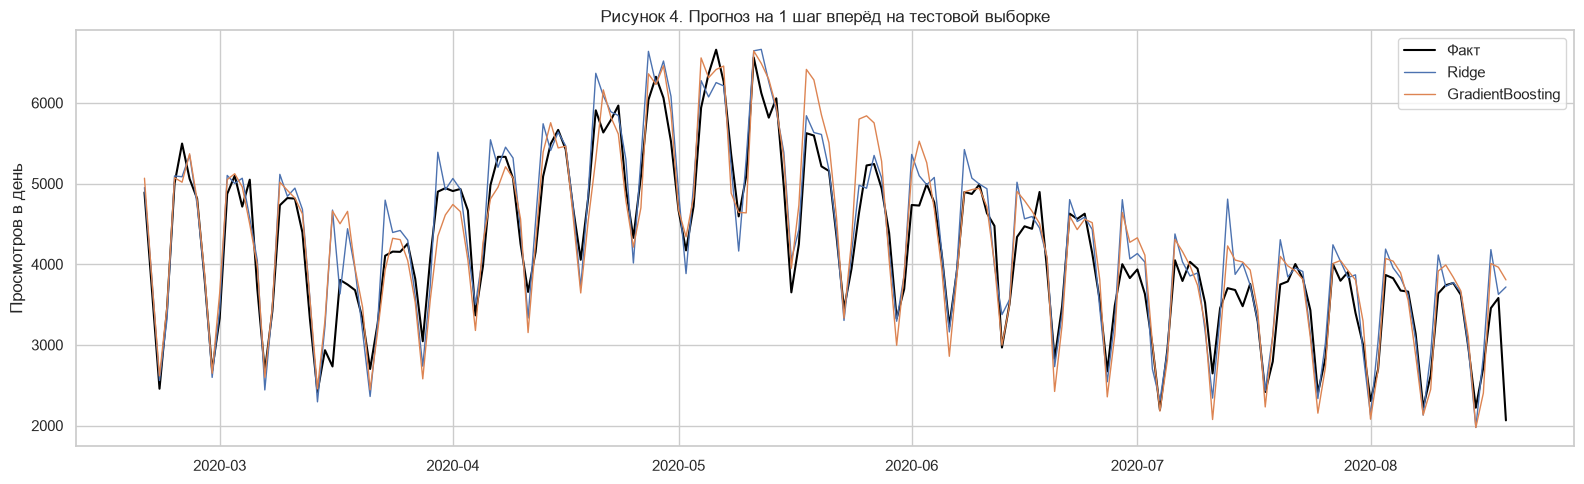

In [16]:
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(y_test, color='black', lw=1.5, label='Факт')
for name in ['Ridge', 'GradientBoosting']:
    ax.plot(y_test.index, models[name].predict(X_test), lw=1, label=name)
ax.set_title('Рисунок 4. Прогноз на 1 шаг вперёд на тестовой выборке')
ax.set_ylabel('Просмотров в день')
ax.legend()
plt.tight_layout()
plt.show()

**Рисунок 4.** Обе модели точно повторяют недельный цикл и общий уровень ряда: весенний рост до 6000–6500 в апреле–мае и летний спад до 3500–4000. Заметно хуже прогноз в середине марта 2020 года: посещаемость упала из-за перехода на дистанционное обучение, а модели ожидали обычную неделю и ошиблись в большую сторону. Ошибка исчезает примерно через неделю, когда новые значения попадают в лаги. Бустинг чаще ошибается на пиках (конец мая, начало июня).

In [17]:
coefs = pd.Series(models['Ridge'][-1].coef_, index=FEATURES)
coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(12).round(1).to_frame('Коэффициент Ridge')

,Коэффициент Ridge
lag_1,965.8
dow_4,-425.1
same_dow_mean_4,342.7
dow_5,-341.3
dow_1,-337.5
roll_mean_28,-335.8
dow_3,-319.9
dow_2,-291.7
is_weekend,-250.6
roll_min_7,247.1


Коэффициенты получены на стандартизированных признаках, их можно сравнивать по модулю. Самый важный признак — `lag_1`, вчерашнее значение (+966): оно задаёт текущий уровень ряда. Следующие по важности — среднее за 4 прошлых таких же дня недели (`same_dow_mean_4`, +343) и дни недели.

Коэффициенты дней недели отрицательные даже для вторника и среды, хотя в эти дни просмотров не меньше, чем в понедельник. Их нужно читать вместе с `lag_1`: для понедельника «вчера» — это воскресенье с низкой посещаемостью, а для вторника — понедельник с высокой. Поправка за день недели компенсирует то, что `lag_1` в разные дни означает разное.

## 5. Прогноз на горизонт H: рекурсивная стратегия

Прогнозируем на $H = 28$ дней (4 недели) вперёд. Используем рекурсивную стратегию: модель прогнозирует на 1 день, прогноз дописывается в ряд как будто это факт, и из этого ряда строятся признаки для следующего дня. Начиная со второго шага лаги и скользящие статистики частично состоят из собственных прогнозов модели.

Чтобы оценка не зависела от одной случайной точки старта, прогноз строится с каждого понедельника тестового периода, для которого все 28 дней лежат внутри теста. Модели обучены только на обучающей выборке; на момент прогноза известны факты до дня перед стартом.

In [18]:
H = 28
HISTORY = 400  # хватает для лага 364 и окна 28


def recursive_forecast(model, history, horizon=H, features=FEATURES, builder=make_features):
    """Рекурсивный прогноз: каждый прогноз дописывается в ряд и становится лагом для следующего шага."""
    hist = history.iloc[-HISTORY:].copy()
    preds = []
    for _ in range(horizon):
        next_day = hist.index[-1] + pd.Timedelta(days=1)
        hist.loc[next_day] = np.nan
        x = builder(hist).iloc[[-1]][features]
        hist.loc[next_day] = model.predict(x)[0]
        preds.append(hist.loc[next_day])
    return pd.Series(preds, index=hist.index[-horizon:])


def evaluate_horizon(model, **kwargs):
    """Прогноз с каждого понедельника тестового периода, для которого горизонт целиком попадает в тест."""
    origins = [d for d in y_test.index if d.dayofweek == 0 and d + pd.Timedelta(days=H - 1) <= y_test.index[-1]]
    forecasts = []
    for origin in origins:
        pred = recursive_forecast(model, y[:origin - pd.Timedelta(days=1)], **kwargs)
        forecasts.append(pd.DataFrame({'origin': origin, 'h': np.arange(1, H + 1),
                                       'pred': pred.values, 'fact': y[pred.index].values}, index=pred.index))
    return pd.concat(forecasts)


horizon_res = {name: evaluate_horizon(models[name]) for name in ['Сезонный наивный', 'Ridge', 'GradientBoosting']}
print('Число стартовых точек прогноза:', horizon_res['Ridge']['origin'].nunique())
pd.DataFrame({name: metrics(r['fact'], r['pred']) for name, r in horizon_res.items()}).T.round(2)

Число стартовых точек прогноза: 22


,MSE,MAE,"MAPE, %","WAPE, %"
Сезонный наивный,545420.05,582.23,13.91,13.62
Ridge,304393.10,430.93,10.65,10.08
GradientBoosting,365801.46,470.56,11.42,11.00


Сезонный наивный прогноз на горизонт тоже считается рекурсивно: на шагах 8–28 он повторяет уже не факт, а собственный прогноз, то есть последнюю известную неделю.

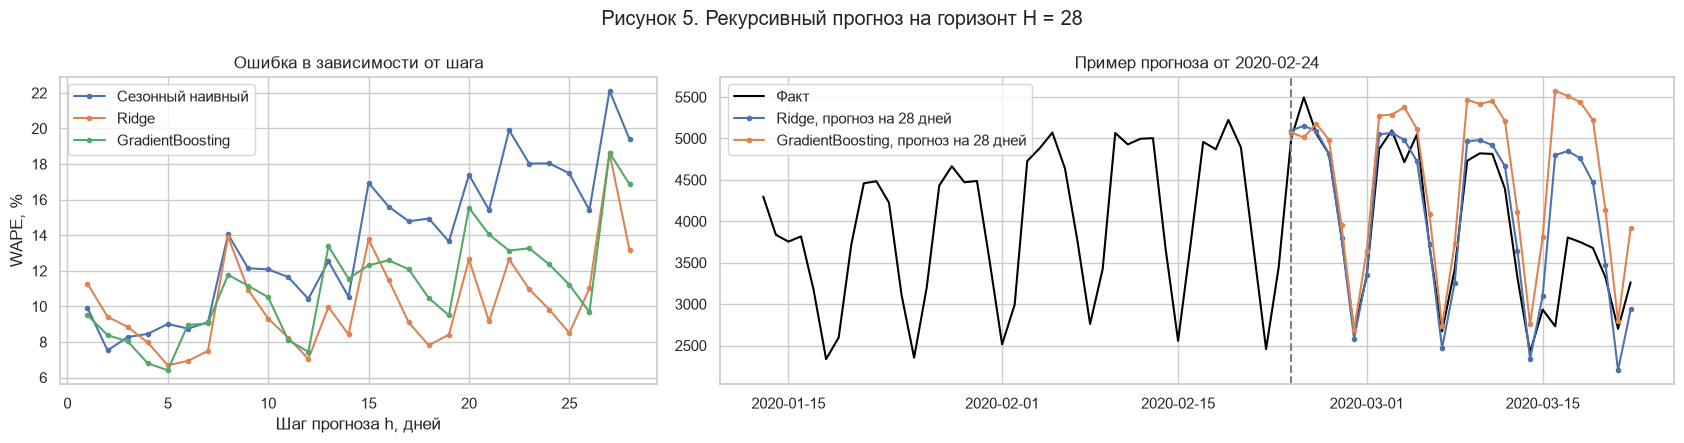

,Сезонный наивный,Ridge,GradientBoosting
"WAPE, %",,,
Неделя 1 (h = 1–7),8.69,8.53,8.13
Неделя 2 (h = 8–14),11.96,9.79,10.45
Неделя 3 (h = 15–21),15.48,10.30,12.21
Неделя 4 (h = 22–28),18.48,11.75,13.31


In [19]:
def wape(res):
    return np.abs(res['fact'] - res['pred']).sum() / res['fact'].sum() * 100


fig, axes = plt.subplots(1, 2, figsize=(17, 4.5), gridspec_kw={'width_ratios': [1, 1.6]})
for name, res in horizon_res.items():
    axes[0].plot(res.groupby('h').apply(wape), marker='o', ms=3, label=name)
axes[0].set_xlabel('Шаг прогноза h, дней')
axes[0].set_ylabel('WAPE, %')
axes[0].set_title('Ошибка в зависимости от шага')
axes[0].legend()

origin = horizon_res['Ridge']['origin'].unique()[0]
axes[1].plot(y[origin - pd.Timedelta(days=42):origin + pd.Timedelta(days=H - 1)], color='black', label='Факт')
for name in ['Ridge', 'GradientBoosting']:
    r = horizon_res[name]
    axes[1].plot(r[r['origin'] == origin]['pred'], marker='o', ms=3, label=f'{name}, прогноз на {H} дней')
axes[1].axvline(origin, color='gray', linestyle='--')
axes[1].set_title(f'Пример прогноза от {origin.date()}')
axes[1].legend()
fig.suptitle(f'Рисунок 5. Рекурсивный прогноз на горизонт H = {H}')
plt.tight_layout()
plt.show()

pd.DataFrame({name: res.groupby((res['h'] - 1) // 7 + 1).apply(wape) for name, res in horizon_res.items()}).rename(
    index=lambda w: f'Неделя {w} (h = {7 * w - 6}–{7 * w})').round(2).rename_axis('WAPE, %')

**Рисунок 5 и таблица.**

- **На горизонте 28 дней лучше всех Ridge:** WAPE 10.1% против 11.0% у бустинга и 13.6% у сезонного наивного прогноза. По сравнению с прогнозом на 1 шаг (WAPE 6.0%) ошибка выросла в 1.7 раза.
- **Ошибка растёт с шагом.** Каждый следующий прогноз опирается на предыдущие, и ошибки накапливаются. По одному шагу график неровный (всего 22 стартовые точки, на каждый шаг приходятся конкретные даты), поэтому в таблице ошибка усреднена по неделям горизонта. У Ridge WAPE растёт с 8.5% в первую неделю до 11.8% в четвёртую, у сезонного наивного прогноза — с 8.7% до 18.5%.
- **Преимущество моделей растёт с горизонтом.** В первую неделю все три метода почти равны (WAPE 8.1–8.7%, бустинг даже немного лучше), а в четвёртую Ridge ошибается на 11.8%, бустинг на 13.3%, наивный прогноз на 18.5%. Наивный прогноз просто повторяет последнюю неделю и не видит, что уровень ряда меняется, а модели учитывают месяц, значение год назад и скользящие средние.
- **Пример от 24.02.2020** (правый график) показывает главное ограничение: первые 2 недели прогноз близок к факту, а с 16 марта посещаемость резко упала из-за COVID-19. Модель продолжает недельный цикл на прежнем уровне — предсказать такой сдвиг по прошлым значениям ряда невозможно.

## 6. Где модель ошибается сильнее

Тестовый период (февраль–август 2020) не содержит Рождества и других зимних праздников. Поэтому для анализа ошибок объединяем прогнозы Ridge на валидационных фолдах кросс-валидации (каждый фолд модель не видела при обучении) и на тесте — получается 637 дней с ноября 2018 года.

Прогнозов вне обучения: 637 (2018-11-22 — 2020-08-19)


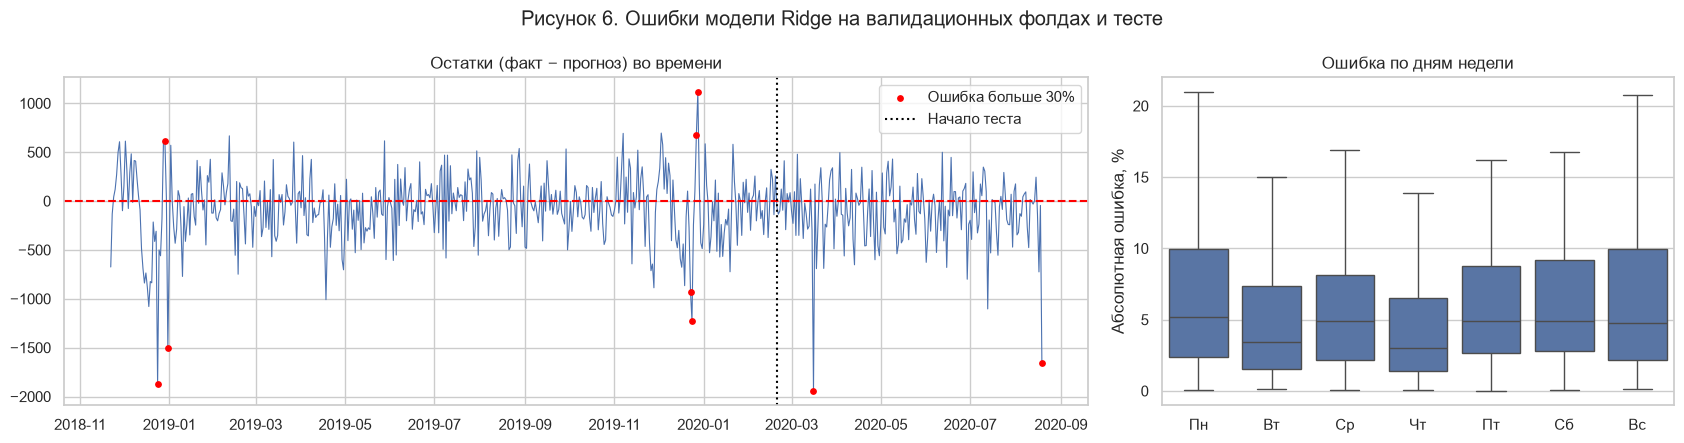

In [20]:
BEST = 'Ridge'
oos = pd.concat([cv_preds[BEST], pd.Series(models[BEST].predict(X_test), index=X_test.index)])
err = pd.DataFrame({'fact': y[oos.index], 'pred': oos})
err['error'] = err['fact'] - err['pred']
err['abs_pct'] = (err['error'].abs() / err['fact'] * 100)
err['dow'] = err.index.dayofweek
err['holiday'] = err.index.isin(HOLIDAYS)
err['xmas'] = X_all.loc[err.index, 'xmas_break'].astype(bool)
print('Прогнозов вне обучения:', len(err), f'({err.index.min().date()} — {err.index.max().date()})')

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5), gridspec_kw={'width_ratios': [2, 1]})
axes[0].plot(err['error'], lw=0.8)
axes[0].axhline(0, color='red', linestyle='--')
big = err[err['abs_pct'] > 30]
axes[0].scatter(big.index, big['error'], color='red', s=15, zorder=3, label='Ошибка больше 30%')
axes[0].axvline(X_test.index[0], color='black', linestyle=':', label='Начало теста')
axes[0].set_title('Остатки (факт − прогноз) во времени')
axes[0].legend()
sns.boxplot(x=err['dow'], y=err['abs_pct'], ax=axes[1], showfliers=False)
axes[1].set_xticks(range(7), DAYS)
axes[1].set_xlabel('')
axes[1].set_ylabel('Абсолютная ошибка, %')
axes[1].set_title('Ошибка по дням недели')
fig.suptitle(f'Рисунок 6. Ошибки модели {BEST} на валидационных фолдах и тесте')
plt.tight_layout()
plt.show()

In [21]:
groups = {
    'Обычные будни': (err['dow'] < 5) & ~err['holiday'] & ~err['xmas'],
    'Выходные': (err['dow'] >= 5) & ~err['holiday'] & ~err['xmas'],
    'Праздники': err['holiday'],
    'Рождественские каникулы': err['xmas'],
}
pd.DataFrame({g: {'Дней': m.sum(), 'MAE': err.loc[m, 'error'].abs().mean(), 'MAPE, %': err.loc[m, 'abs_pct'].mean(),
                  'Средняя ошибка': err.loc[m, 'error'].mean()} for g, m in groups.items()}).T.round(1)

,Дней,MAE,"MAPE, %",Средняя ошибка
Обычные будни,422.0,254.5,5.6,-98.3
Выходные,174.0,199.7,6.5,-31.2
Праздники,17.0,334.4,11.1,-183.8
Рождественские каникулы,28.0,549.6,27.7,-222.9


In [22]:
top = err.reindex(err['abs_pct'].sort_values(ascending=False).index).head(10)
top.assign(day=[DAYS[d] for d in top['dow']])[['fact', 'pred', 'abs_pct', 'day']].round(1)

,fact,pred,abs_pct,day
Date,,,,
2018-12-24,1835.0,3710.5,102.2,Пн
2018-12-31,1723.0,3222.9,87.1,Пн
2020-08-19,2064.0,3717.6,80.1,Ср
2019-12-24,1644.0,2870.8,74.6,Вт
2020-03-16,2732.0,4670.9,71.0,Пн
2019-12-28,1679.0,562.7,66.5,Сб
2019-12-23,2451.0,3379.3,37.9,Пн
2018-12-29,1694.0,1083.9,36.0,Сб
2019-12-27,1927.0,1247.1,35.3,Пт


**Рисунок 6 и таблицы.**

- **Сильнее всего модель ошибается на рождественских каникулах:** MAPE 27.7% против 5.6% в обычные будни, то есть почти в 5 раз больше. Средняя ошибка −223: модель в среднем завышает прогноз. В первые дни каникул (23–24 и 31 декабря) лаги ещё «помнят» обычную посещаемость, и прогноз в 1.5–2 раза выше факта (24.12.2018: 3711 вместо 1835). Признак `xmas_break` действует одинаково на все 14 дней каникул, а реальная посещаемость внутри них сильно меняется. Встречается и обратная ошибка: 28.12.2019 (суббота) модель дала 563 вместо 1679 — в линейной модели поправки за выходной, каникулы и низкие лаги складываются и «перекручивают» прогноз вниз.
- **На федеральных праздниках** MAPE 11.1% — в 2 раза больше, чем в будни. Праздников мало (17 дней за 637), и каждый влияет на посещаемость по-своему.
- **Выбросы, которых нет в признаках:** 16.03.2020 (переход на дистанционное обучение, ошибка 71%) и 19.08.2020 (неполный последний день, ошибка 80%). Такие события по прошлому ряда не прогнозируются.
- **По дням недели** ошибка выше всего в понедельник (медиана около 5%, широкий разброс): прогноз на понедельник строится после выходных, и `lag_1` хуже всего описывает предстоящий день. Во вторник и четверг ошибка минимальна (медиана около 3%).
- **Тренд и сезонность модель отслеживает хорошо:** вне праздников остатки колеблются вокруг нуля без заметного смещения на всём периоде, в том числе на весеннем пике и летнем спаде 2020 года.

## 7. STL-декомпозиция

STL (Seasonal and Trend decomposition using Loess) раскладывает ряд на сумму трёх компонент: $y_t = T_t + S_t + R_t$ — тренд, сезонность и остаток. Параметр `robust=True` уменьшает влияние выбросов (праздников) на тренд и сезонность.

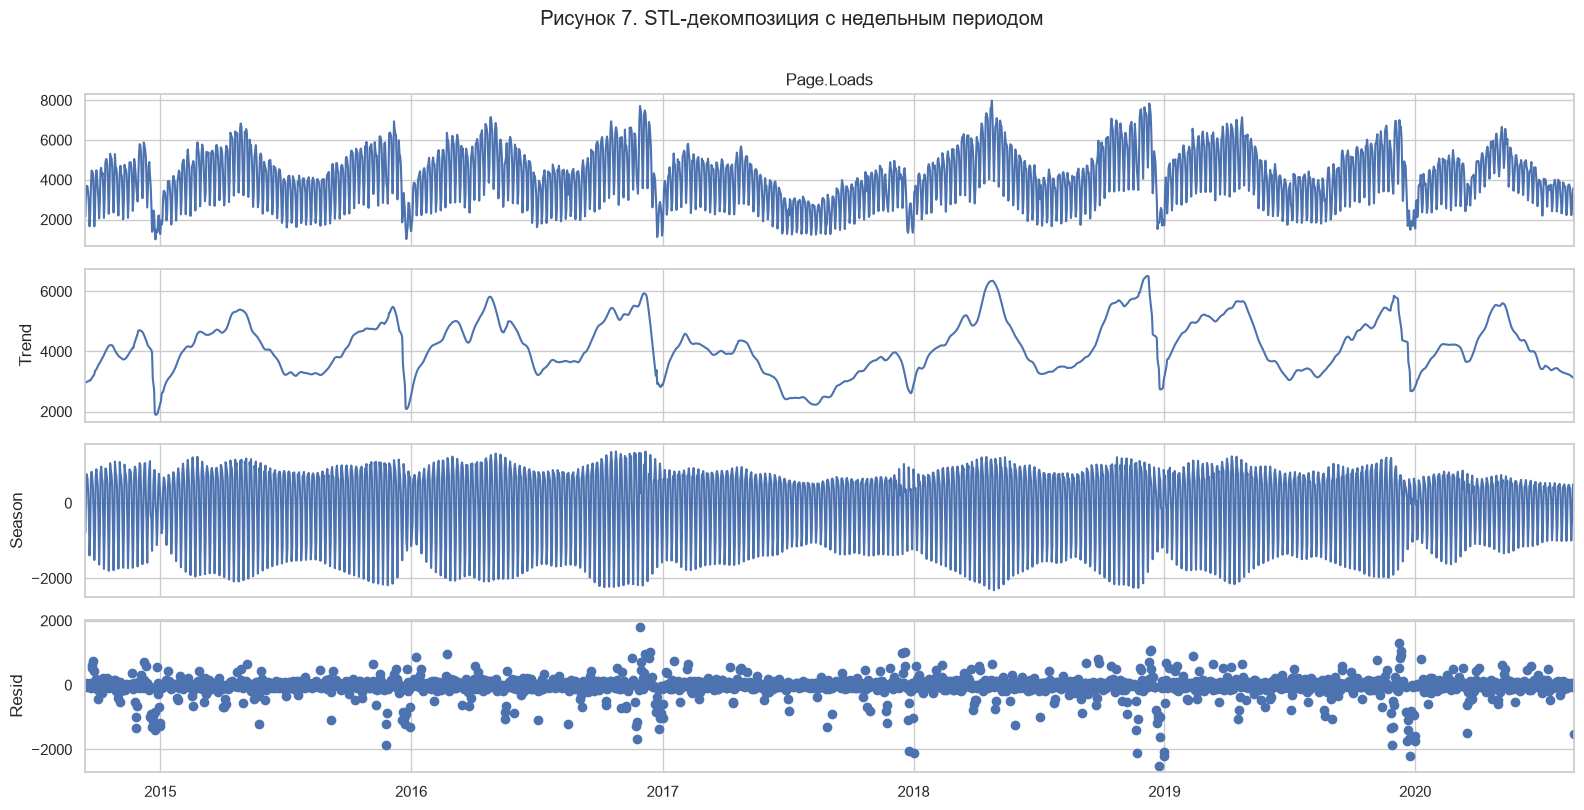

In [23]:
stl = STL(y, period=7, robust=True).fit()
fig = stl.plot()
fig.set_size_inches(16, 8)
fig.suptitle('Рисунок 7. STL-декомпозиция с недельным периодом', y=1.01)
plt.tight_layout()
plt.show()

**Рисунок 7.** STL выделяет одну сезонность с заданным периодом — здесь 7 дней.

- **Сезонная компонента** — недельный цикл. Его размах меняется: в учебные месяцы примерно ±2000, летом и в 2017 году около ±1000. Размах сезонности пропорционален уровню ряда, то есть сезонность скорее мультипликативная, чем аддитивная.
- **Тренд** с недельным периодом забирает в себя всю годовую сезонность: подъём весной и осенью, спад летом и провал на Рождество.
- **Остатки** небольшие в обычное время, крупные выбросы до −2500 — на рождественских каникулах.

Чтобы разделить годовую сезонность и тренд, используем MSTL — вариант STL с несколькими сезонными периодами (7 и 364 дня).

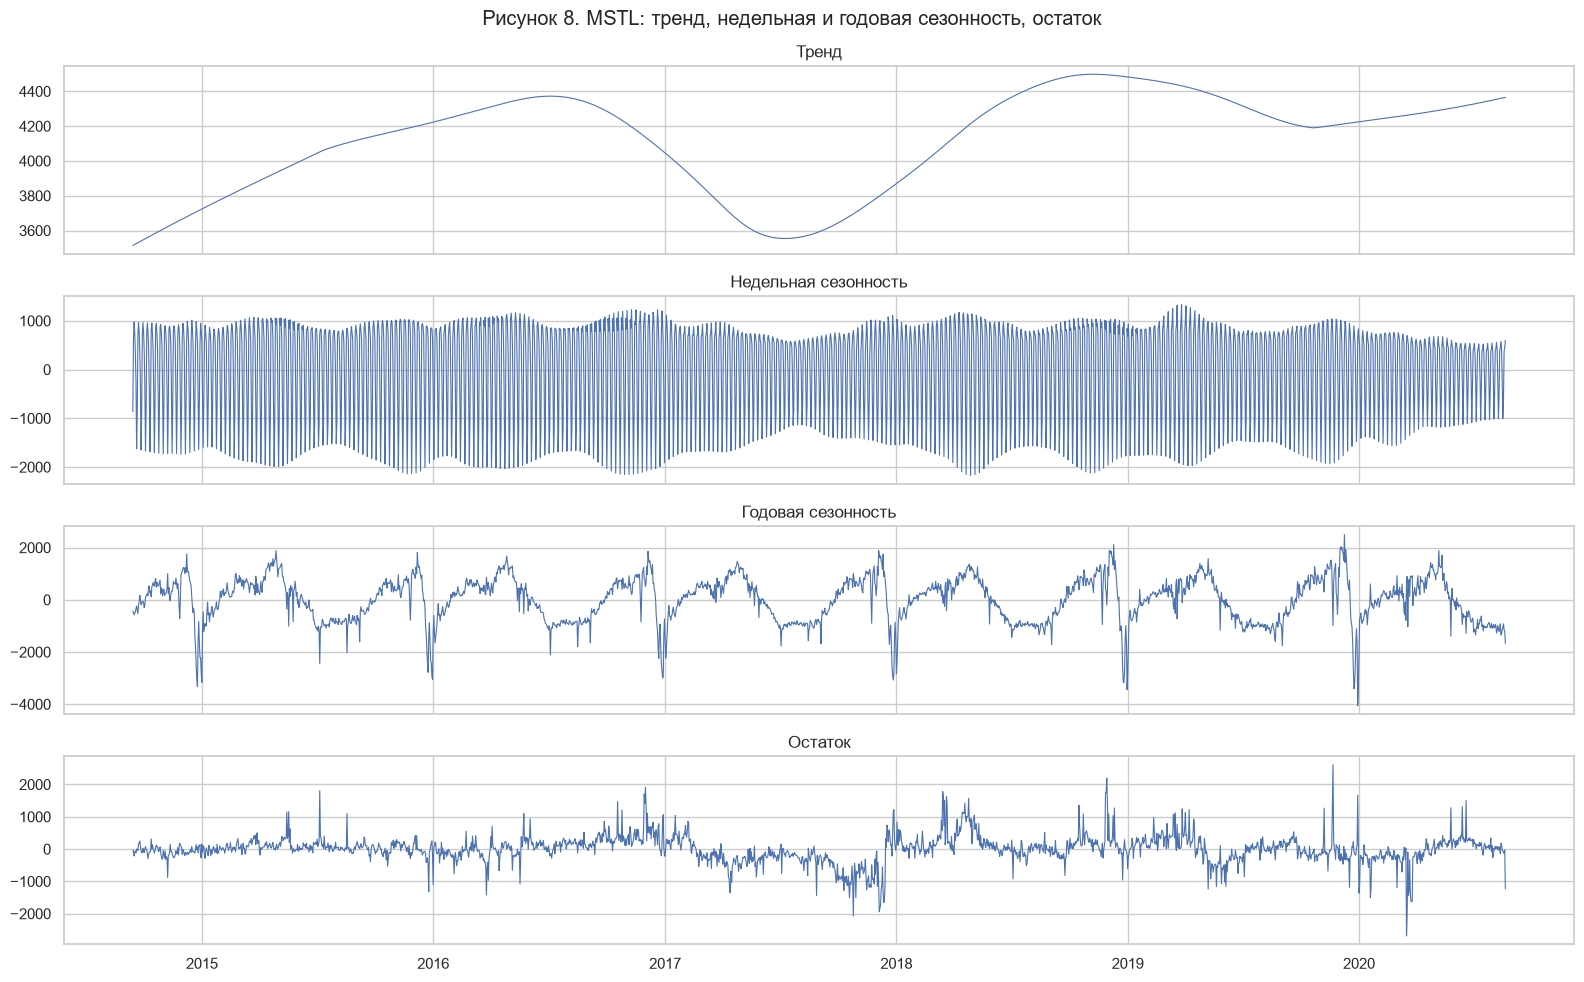

,Дисперсия,"Доля от ряда, %"
Ряд,1825141.1,100.0
Тренд,79176.5,4.3
Недельная,918616.4,50.3
Годовая,741878.2,40.6
Остаток,179044.1,9.8


In [24]:
mstl = MSTL(y, periods=(7, 364), stl_kwargs={'robust': True}).fit()
fig, axes = plt.subplots(4, 1, figsize=(16, 10), sharex=True)
for ax, (comp, title) in zip(axes, [(mstl.trend, 'Тренд'), (mstl.seasonal['seasonal_7'], 'Недельная сезонность'),
                                    (mstl.seasonal['seasonal_364'], 'Годовая сезонность'), (mstl.resid, 'Остаток')]):
    ax.plot(comp, lw=0.8)
    ax.set_title(title)
fig.suptitle('Рисунок 8. MSTL: тренд, недельная и годовая сезонность, остаток')
plt.tight_layout()
plt.show()

pd.DataFrame({'Дисперсия': [y.var(), mstl.trend.var(), mstl.seasonal['seasonal_7'].var(),
                            mstl.seasonal['seasonal_364'].var(), mstl.resid.var()]},
             index=['Ряд', 'Тренд', 'Недельная', 'Годовая', 'Остаток']).assign(
    **{'Доля от ряда, %': lambda d: d['Дисперсия'] / y.var() * 100}).round(1)

**Рисунок 8 и таблица.**

- **Тренд** плавный, меняется в пределах 3500–4500: рост в 2015–2016 годах, спад к середине 2017, восстановление к концу 2018 и почти ровный уровень потом. На него приходится всего 4.3% дисперсии ряда.
- **Недельная сезонность** объясняет 50.3% дисперсии — больше всех остальных компонент.
- **Годовая сезонность** — 40.6%: два подъёма (весенний семестр с пиком в апреле и осенний с пиком в ноябре — начале декабря), летний спад около −1000 и глубокий провал до −3000…−4000 на Рождество.
- **Остаток** — 9.8% дисперсии. В нём видны отклонения 2017 года (весь год ниже обычного) и праздничные выбросы.

Компоненты в сумме объясняют около 90% дисперсии ряда. Это подтверждает выводы раздела 1: ряд определяется в основном двумя сезонностями, а тренд слабый.

### Признаки на основе декомпозиции

Проверим, улучшают ли прогноз компоненты декомпозиции. Брать компоненты, посчитанные по всему ряду (рисунки 7–8), нельзя: LOESS сглаживает с обеих сторон, и тренд в точке $t$ зависит от значений после $t$ — это утечка.

Поэтому для каждой даты $t$ STL обучается заново только на последних 364 днях до $t$, и из результата берутся:

- `stl_trend` — тренд в $t-1$ (текущий уровень ряда без недельного цикла);
- `stl_trend_slope` — изменение тренда за последнюю неделю;
- `stl_seasonal` — сезонная поправка для того же дня недели (в $t-7$);
- `stl_resid` — остаток в $t-1$;
- `stl_naive` — тренд + сезонная поправка, готовый прогноз по декомпозиции.

Ячейка выполняется 1–2 минуты: STL обучается 1803 раза.

In [25]:
STL_WINDOW = 364


def stl_features(y, positions):
    """STL на окне из STL_WINDOW прошлых дней перед каждой позицией: компоненты известны на момент прогноза."""
    rows = {}
    for i in positions:
        window = y.iloc[i - STL_WINDOW:i].to_numpy()
        if i < STL_WINDOW or np.isnan(window).any():
            continue
        res = STL(window, period=7, robust=True).fit()
        rows[y.index[i]] = {
            'stl_trend': res.trend[-1],
            'stl_trend_slope': res.trend[-1] - res.trend[-8],
            'stl_seasonal': res.seasonal[-7],
            'stl_resid': res.resid[-1],
            'stl_naive': res.trend[-1] + res.seasonal[-7],
        }
    return pd.DataFrame.from_dict(rows, orient='index')


def make_features_stl(y):
    """Обычные признаки + признаки декомпозиции для последней даты ряда (используется в рекурсивном прогнозе)."""
    return make_features(y).join(stl_features(y, [len(y) - 1]))


positions = [y.index.get_loc(d) for d in data.index]
STL_X = stl_features(y, positions)
STL_FEATURES = FEATURES + list(STL_X.columns)
data_stl = data.join(STL_X)
X_train_stl, X_test_stl = data_stl.loc[train.index, STL_FEATURES], data_stl.loc[test.index, STL_FEATURES]
data_stl[list(STL_X.columns)].describe().round(1)

,stl_trend,stl_trend_slope,stl_seasonal,stl_resid,stl_naive
count,1803.0,1803.0,1803.0,1803.0,1803.0
mean,4160.7,-23.6,-1.3,5.8,4159.4
std,1027.6,426.5,969.9,200.5,1427.5
min,662.2,-2718.1,-2598.9,-2311.1,-845.1
25%,3479.7,-181.8,-784.1,-36.1,3109.8
50%,4135.7,32.9,428.9,-1.0,4159.8
75%,4904.2,218.0,778.2,36.4,5131.4
max,6746.7,1306.4,2106.5,2231.6,8109.0


In [26]:
models_stl = {
    'Ridge': GridSearchCV(make_pipeline(StandardScaler(), Ridge()), {'ridge__alpha': np.logspace(-4, 3, 36)},
                          cv=tscv, scoring='neg_mean_absolute_error').fit(X_train_stl, y_train).best_estimator_,
    'GradientBoosting': clone(models['GradientBoosting']),
}

rows = {}
for name, model in models_stl.items():
    model.fit(X_train_stl, y_train)
    for label, X_tr, X_te, m in [('без STL', X_train, X_test, models[name]),
                                 ('с STL', X_train_stl, X_test_stl, model)]:
        cv_mean = time_cv(m, X_tr, y_train)[0].mean()
        test_m = metrics(y_test, m.predict(X_te))
        rows[(name, label)] = {'MAE (CV)': cv_mean['MAE'], 'WAPE (CV), %': cv_mean['WAPE, %'],
                               'MAE (тест)': test_m['MAE'], 'MAPE (тест), %': test_m['MAPE, %'],
                               'WAPE (тест), %': test_m['WAPE, %']}
stl_compare = pd.DataFrame(rows).T
stl_compare.round(2)

MAE (CV)  WAPE (CV), %  MAE (тест)  MAPE (тест), %  \
Ridge            без STL    256.14          6.04      248.69            6.44   
                 с STL      254.84          6.01      245.25            6.33   
GradientBoosting без STL    306.74          7.18      285.47            7.36   
                 с STL      296.55          6.95      257.19            6.81   

                          WAPE (тест), %  
Ridge            без STL            5.95  
                 с STL              5.87  
GradientBoosting без STL            6.83  
                 с STL              6.15

**Прогноз на 1 шаг: признаки декомпозиции помогают.**

- **Ridge** — улучшение небольшое: MAE на тесте 249 → 245, WAPE 5.95% → 5.87%, по кросс-валидации MAE 256 → 255. Почти всю информацию о уровне и недельной сезонности уже дают скользящие средние и `same_dow_mean_4`.
- **Бустинг** — улучшение заметное: MAE на тесте 285 → 257 (на 10%), WAPE 6.83% → 6.15%, по кросс-валидации MAE 307 → 297. Деревьям трудно самим составить из 42 признаков «уровень + поправка за день недели», а `stl_naive` даёт эту комбинацию в готовом виде.

Ridge с признаками STL остаётся лучшей моделью. Проверим её на горизонте 28 дней.

In [27]:
best_stl = min(models_stl, key=lambda n: stl_compare.loc[(n, 'с STL'), 'MAE (CV)'])
horizon_stl = evaluate_horizon(models_stl[best_stl], features=STL_FEATURES, builder=make_features_stl)
pd.DataFrame({
    f'{best_stl} без STL': metrics(horizon_res[best_stl]['fact'], horizon_res[best_stl]['pred']),
    f'{best_stl} с STL': metrics(horizon_stl['fact'], horizon_stl['pred']),
}).T.round(2)

,MSE,MAE,"MAPE, %","WAPE, %"
Ridge без STL,304393.1,430.93,10.65,10.08
Ridge с STL,332139.1,450.62,11.14,10.54


**Прогноз на горизонт 28 дней: признаки декомпозиции не помогают.** WAPE Ridge вырос с 10.1% до 10.5%, MAE — с 431 до 451.

При рекурсивном прогнозе STL на каждом шаге обучается на окне, конец которого состоит из собственных прогнозов модели. Оценка тренда на краю окна у STL и так неустойчивая (LOESS видит данные только с одной стороны), а здесь она строится ещё и по прогнозам, поэтому ошибка в тренде переходит в следующие шаги и накапливается.

Итог: компоненты декомпозиции немного улучшают прогноз на 1 шаг (особенно для бустинга), но на длинном горизонте рекурсивной стратегии их польза пропадает.

## Итоговая таблица метрик

In [28]:
summary = pd.concat({
    '1 шаг, train': one_step.xs('train', level=1),
    '1 шаг, test': one_step.xs('test', level=1),
    f'H = {H}, test': pd.DataFrame({n: metrics(r['fact'], r['pred']) for n, r in horizon_res.items()}).T,
})
summary.round(2)

MSE     MAE  MAPE, %  WAPE, %
1 шаг, train Сезонный наивный  409163.57  417.00    11.45    10.02
             Linear             89593.46  224.21     6.20     5.38
             Ridge              89593.46  224.21     6.20     5.38
             GradientBoosting   18264.33  103.02     2.82     2.47
1 шаг, test  Сезонный наивный  216672.02  350.18     8.81     8.38
             Linear            123950.65  248.69     6.44     5.95
             Ridge             123950.59  248.69     6.44     5.95
             GradientBoosting  146513.35  285.47     7.36     6.83
H = 28, test Сезонный наивный  545420.05  582.23    13.91    13.62
             Ridge             304393.10  430.93    10.65    10.08
             GradientBoosting  365801.46  470.56    11.42    11.00

## Выводы

1. **Данные.** Ряд ежедневных просмотров учебного сайта (2167 дней, 2014–2020) полный, без пропусков и дублей. В нём сильная недельная сезонность (в будни около 4900 просмотров, в субботу около 2450) и годовая, связанная с учебным годом: пики в апреле и ноябре, спад летом, глубокий провал на Рождество. Тренд слабый. Выбросы — почти исключительно рождественские каникулы, а также переход на дистанционное обучение 16.03.2020 и неполный последний день ряда. По MSTL недельная сезонность объясняет 50% дисперсии ряда, годовая — 41%, тренд — 4%.
2. **Признаки.** Построено 42 признака только по прошлому: календарные (день недели, месяц, год, выходной, праздник, рождественские каникулы), лаги 1–7, скользящие среднее, медиана, стандартное отклонение, min и max за 7 и 28 дней, значения неделю, две недели и год (364 дня) назад. Отсутствие утечки проверено.
3. **Валидация.** Тест — последние 182 дня. Кросс-валидация по времени с расширяющимся окном оказалась лучше, чем со скользящим: длинная история даёт больше примеров редких праздников.
4. **Прогноз на 1 шаг.** Лучшая модель — Ridge (на практике совпадает с линейной регрессией, так как оптимальный `alpha` близок к нулю): на тесте MAE 249, MAPE 6.4%, WAPE 6.0%, что почти вдвое лучше сезонного наивного прогноза (WAPE 8.4%). Метрики на train и test близки, переобучения нет. Градиентный бустинг переобучен (WAPE 2.5% на train и 6.8% на test).
5. **Прогноз на 28 дней** рекурсивной стратегией: у Ridge WAPE 10.1% против 13.6% у сезонного наивного прогноза. Ошибка растёт с горизонтом из-за накопления ошибок в лагах.
6. **Где модель ошибается.** Сильнее всего — на рождественских каникулах (MAPE 28% против 6% в обычные дни) и на внешних событиях вроде перехода на дистанционное обучение в марте 2020. Тренд и сезонность модель отслеживает хорошо.
7. **Декомпозиция.** Признаки STL, посчитанные без утечки (по прошлому окну), немного улучшают прогноз на 1 шаг: у Ridge WAPE 5.95% → 5.87%, у бустинга 6.83% → 6.15%. На горизонте 28 дней они ухудшают прогноз Ridge (10.1% → 10.5%), так как STL на краю окна по собственным прогнозам неустойчива.

**Ограничения и как улучшить модель.**

- Модель не знает о внешних событиях (пандемия, изменения на сайте в 2017 году) и не может их предсказать по прошлым значениям ряда.
- Рождественские каникулы описаны одним признаком на все 14 дней, хотя внутри них посещаемость сильно меняется. Можно добавить отдельные признаки для 24, 25 и 31 декабря и номер дня внутри каникул, а также учесть академический календарь (начало и конец семестра, экзамены, весенние каникулы).
- Размах недельной сезонности пропорционален уровню ряда, а линейная модель складывает эффекты. Прогноз логарифма `Page.Loads` сделал бы сезонность аддитивной и, вероятно, уменьшил бы ошибки на праздниках и выходных каникул.
- На длинном горизонте можно попробовать прямую стратегию (отдельная модель для каждого шага), которая не накапливает ошибки собственных прогнозов.